# Field-of-View (Zenith Cap) Cut Example

This example characterizes `FOVSelector`, a cut that rejects events whose Compton circle
falls mostly away from the spacecraft zenith (the instrument's own +z axis), by comparing
an astrophysical point source (the Crab) against an anisotropic background component
(albedo photons, produced in the Earth's atmosphere and therefore expected to reconstruct
preferentially away from the spacecraft zenith during a zenith-pointing survey).


`FOVSelector` is the spacecraft-frame analogue of the Earth horizon cut
(`EHSelector` in `cosipy/event_selection/earth_horizon_selection.py`): both compute, via
the spherical law of cosines, what fraction of an event's Compton circle falls inside a
cap of a given angular radius around some axis, and cut on that fraction. The Earth
horizon cut uses the (time-dependent) Earth zenith as the axis and the Earth-free region
as the cap; `FOVSelector` instead uses the spacecraft's own, fixed, zenith as the axis.
Because that axis doesn't depend on time, `FOVSelector` needs no orientation file.

Parameters:
- `cap_angle`: angular radius of the field-of-view cap around the spacecraft zenith.
- `cutvalue`: minimum fraction of the Compton circle that must fall inside the cap, in [0, 1].


In [1]:
import sys 
sys.path.insert(0, "/localscratch1/sgallego/GrandRemplacement/sandbox-claude/cosipy_add_FOVcut")


from pathlib import Path
import numpy as np
import astropy.units as u
import matplotlib.pyplot as plt

from cosipy.event_selection.fov_selection import FOVSelector
from cosipy.data_io.EmCDSUnbinnedData import TimeTagEmCDSEventDataInSCFrameFromDC3Fits
from cosipy.util import fetch_wasabi_file

%matplotlib inline

17:00:38 WARNING   The naima package is not available. Models that depend on it will not be         ]8;id=2575889;file:///localscratch1/sgallego/miniconda3/envs/cosipy/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py\functions.py]8;;\:]8;id=2575890;file:///localscratch1/sgallego/miniconda3/envs/cosipy/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py#43\43]8;;\
                  available                                                                                        

         WARNING   The GSL library or the pygsl wrapper cannot be loaded. Models that depend on it  ]8;id=2575896;file:///localscratch1/sgallego/miniconda3/envs/cosipy/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py\functions.py]8;;\:]8;id=2575897;file:///localscratch1/sgallego/miniconda3/envs/cosipy/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py#65\65]8;;\
                  will not be available.                                                                           

         WARNING   The ebltable package is not available. Models that depend on it will not be     ]8;id=2575904;file:///localscratch1/sgallego/miniconda3/envs/cosipy/lib/python3.12/site-packages/astromodels/functions/functions_1D/absorption.py\absorption.py]8;;\:]8;id=2575905;file:///localscratch1/sgallego/miniconda3/envs/cosipy/lib/python3.12/site-packages/astromodels/functions/functions_1D/absorption.py#33\33]8;;\
                  available                                                                                        

17:00:39 INFO      Starting 3ML!                                                                     ]8;id=2575912;file:///localscratch1/sgallego/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=2575913;file:///localscratch1/sgallego/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/__init__.py#44\44]8;;\

         WARNING   WARNINGs here are NOT errors                                                      ]8;id=2575919;file:///localscratch1/sgallego/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=2575920;file:///localscratch1/sgallego/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/__init__.py#45\45]8;;\

         WARNING   but are inform you about optional packages that can be installed                  ]8;id=2575926;file:///localscratch1/sgallego/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=2575927;file:///localscratch1/sgallego/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/__init__.py#46\46]8;;\

... (6 outputs left out)

         WARNING   No fermitools installed                                              ]8;id=2575977;file:///localscratch1/sgallego/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py\lat_transient_builder.py]8;;\:]8;id=2575978;file:///localscratch1/sgallego/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py#44\44]8;;\

         WARNING   Env. variable OMP_NUM_THREADS is not set. Please set it to 1 for optimal         ]8;id=2575984;file:///localscratch1/sgallego/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=2575985;file:///localscratch1/sgallego/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/__init__.py#335\335]8;;\
                  performances in 3ML                                                                              

         WARNING   Env. variable MKL_NUM_THREADS is not set. Please set it to 1 for optimal         ]8;id=2575990;file:///localscratch1/sgallego/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=2575991;file:///localscratch1/sgallego/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/__init__.py#335\335]8;;\
                  performances in 3ML                                                                              

         WARNING   Env. variable NUMEXPR_NUM_THREADS is not set. Please set it to 1 for optimal     ]8;id=2575996;file:///localscratch1/sgallego/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=2575997;file:///localscratch1/sgallego/miniconda3/envs/cosipy/lib/python3.12/site-packages/threeML/__init__.py#335\335]8;;\
                  performances in 3ML                                                                              

Download a 3-month unbinned DC3 simulation of the Crab (the source) and of the albedo
photon background component. Both files are per-event, time-tagged, and already in the
spacecraft frame.

In [2]:
path = Path("")
crab_data_path = path / Path("crab_standard_3months_unbinned_data_filtered_with_SAAcut.fits.gz")
fetch_wasabi_file('COSI-SMEX/DC3/Data/Sources/crab_standard_3months_unbinned_data_filtered_with_SAAcut.fits.gz',
                  output=str(crab_data_path), checksum='1d73e7b9e46e51215738075e91a52632')

bkg_data_path = path / Path("AlbedoPhotons_WithDetCstunbinned_data_filtered_with_SAAcut.fits.gz")
fetch_wasabi_file('COSI-SMEX/DC4/Data/Backgrounds/AlbedoPhotons_WithDetCstunbinned_data_filtered_with_SAAcut.fits.gz',
                  output=str(bkg_data_path), checksum='bbeb2bd8f5b025d77fa96f76834be4a2')

Read the unbinned source and background event files separately (so the signal-retained
and background-rejected fractions can be tracked independently), directly in the
spacecraft frame. No orientation file or time selection is needed: the FOV cap cut only
depends on each event's own scattering angle `phi` and the spacecraft-frame colatitude
`psi` of its psichi direction.

In [3]:
source_events = TimeTagEmCDSEventDataInSCFrameFromDC3Fits(crab_data_path)
bkg_events = TimeTagEmCDSEventDataInSCFrameFromDC3Fits(bkg_data_path)

print(f"Source (Crab) events: {source_events.nevents:,}")
print(f"Background (albedo photons) events: {bkg_events.nevents:,}")

Source (Crab) events: 4,637,632
Background (albedo photons) events: 27,081,364


For every event, compute `phi` (the Compton scattering angle) and `psi` (the colatitude
of the psichi direction from the spacecraft zenith), and the fraction of the Compton
circle that falls inside a fixed-radius cap around the zenith. This reuses the same
spherical-cap-fraction calculation as the Earth horizon cut
(`EHSelector.calculate_sky_fraction`), here applied to the spacecraft zenith cap instead
of the Earth-free region.

In [4]:
def in_cap_fraction(events, cap_angle):
    phi = events.scattering_angle_rad
    psi = np.pi / 2 - events.scattered_lat_rad_sc
    return FOVSelector.calculate_cap_fraction(np.cos(psi), phi, np.cos(cap_angle.to_value(u.rad)))

cap_angle = 45 * u.deg

ffov_source = in_cap_fraction(source_events, cap_angle)
ffov_bkg = in_cap_fraction(bkg_events, cap_angle)

Distribution of the in-cap fraction for the source and the background, for a
45 deg cap. If albedo photons do pile up away from the zenith as expected, their
distribution should be shifted towards low `f_fov` relative to the Crab.

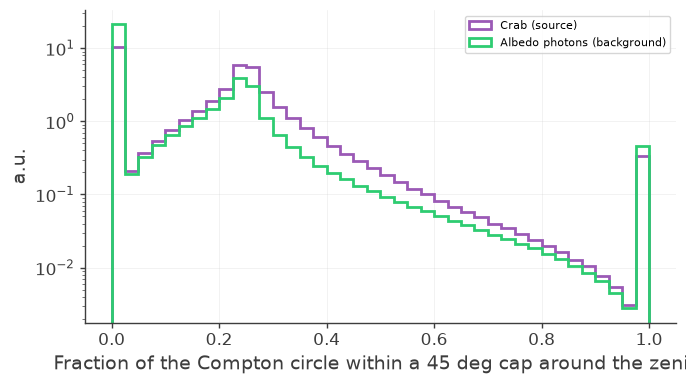

In [6]:
bins = np.linspace(0, 1, 41)

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(ffov_source, bins=bins, density=True, histtype="step", linewidth=2, label="Crab (source)")
ax.hist(ffov_bkg, bins=bins, density=True, histtype="step", linewidth=2, label="Albedo photons (background)")
ax.set_xlabel(f"Fraction of the Compton circle within a {cap_angle.to_value(u.deg):.0f} deg cap around the zenith")
ax.set_ylabel("a.u.")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
ax.set_yscale("log")

Characterize the cut: scan the cut threshold `cutvalue` and, for a few choices of the
FOV cap radius, trace out the fraction of signal retained vs. the fraction of background
rejected (an ROC-like curve). A cut that is actually separating the two populations will
bow towards the top-left corner (most background rejected for the least signal lost).

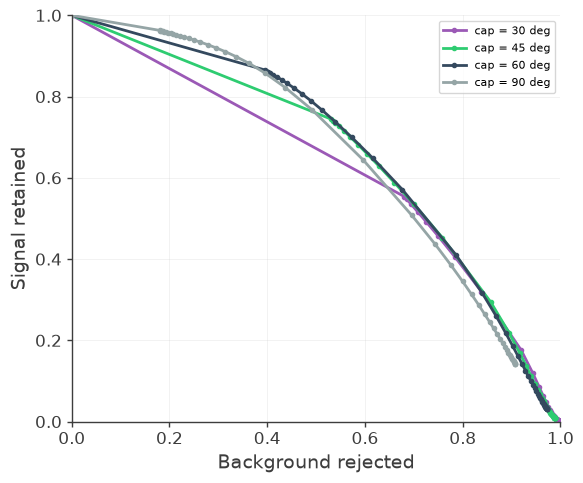

In [9]:
cap_angles = [30, 45, 60, 90] * u.deg
cutvalues = np.linspace(0, 1, 51)

fig, ax = plt.subplots(figsize=(6, 5))

for cap_angle_i in cap_angles:
    ffov_source_i = in_cap_fraction(source_events, cap_angle_i)
    ffov_bkg_i = in_cap_fraction(bkg_events, cap_angle_i)

    signal_retained = np.array([np.mean(ffov_source_i >= c) for c in cutvalues])
    bkg_rejected = np.array([1 - np.mean(ffov_bkg_i >= c) for c in cutvalues])

    ax.plot(bkg_rejected, signal_retained, marker='.', label=f"cap = {cap_angle_i.to_value(u.deg):.0f} deg")

ax.set_xlabel("Background rejected")
ax.set_ylabel("Signal retained")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()

Pick an operating point and apply it as an actual cut, the same way `FOVSelector`
would be used in an analysis: pass it as `selection=` when constructing the event data
reader, exactly like `EHSelector` or `TimeSelector`.

**As with the pointing cut, if this is used in a real analysis (e.g., spectral fitting),
the source data, background, and any other selections need to be applied self-consistently
to both the source and background files.**

In [8]:
chosen_cap_angle = 60 * u.deg
chosen_cutvalue = 0.5

fov_selector = FOVSelector(cap_angle=chosen_cap_angle, cutvalue=chosen_cutvalue)

source_events_cut = TimeTagEmCDSEventDataInSCFrameFromDC3Fits(crab_data_path, selection=fov_selector)
bkg_events_cut = TimeTagEmCDSEventDataInSCFrameFromDC3Fits(bkg_data_path, selection=fov_selector)

signal_retained_frac = source_events_cut.nevents / source_events.nevents
bkg_rejected_frac = 1 - bkg_events_cut.nevents / bkg_events.nevents

print(f"FOV cut: cap = {chosen_cap_angle.to_value(u.deg):.0f} deg, cutvalue = {chosen_cutvalue}")
print(f"Signal:     {source_events.nevents:,} -> {source_events_cut.nevents:,} ({signal_retained_frac:.1%} retained)")
print(f"Background: {bkg_events.nevents:,} -> {bkg_events_cut.nevents:,} ({bkg_rejected_frac:.1%} rejected)")

FOV cut: cap = 60 deg, cutvalue = 0.5
Signal:     4,637,632 -> 519,335 (11.2% retained)
Background: 27,081,364 -> 1,786,511 (93.4% rejected)


`FOVSelector` can be combined with other cuts (energy, distance, time, Earth horizon,
...) using `ChainEventSelectors`, just like any other `EventSelectorInterface`.